In [6]:
import joblib

# Load mô hình XGBoost đã huấn luyện
xgb_model = joblib.load("../models/xgboost.pkl")

# Kiểm tra số lượng đặc trưng
print("Số lượng features:", xgb_model.n_features_in_)

# Kiểm tra tên và thứ tự features
if hasattr(xgb_model, "feature_names_in_"):
    feature_names = xgb_model.feature_names_in_

    print("\nDanh sách features:")
    for i, name in enumerate(feature_names, start=1):
        print(f"{i}. {name}")
else:
    print("\nMô hình không lưu feature_names_in_.")

Số lượng features: 79

Danh sách features:
1. step
2. amount
3. age_'0'
4. age_'1'
5. age_'2'
6. age_'3'
7. age_'4'
8. age_'5'
9. age_'6'
10. age_'U'
11. gender_'E'
12. gender_'F'
13. gender_'M'
14. gender_'U'
15. merchant_'M1053599405'
16. merchant_'M117188757'
17. merchant_'M1198415165'
18. merchant_'M1294758098'
19. merchant_'M1313686961'
20. merchant_'M1352454843'
21. merchant_'M1353266412'
22. merchant_'M1400236507'
23. merchant_'M1416436880'
24. merchant_'M151143676'
25. merchant_'M1535107174'
26. merchant_'M1600850729'
27. merchant_'M1649169323'
28. merchant_'M1726401631'
29. merchant_'M17379832'
30. merchant_'M1741626453'
31. merchant_'M1748431652'
32. merchant_'M1788569036'
33. merchant_'M1823072687'
34. merchant_'M1842530320'
35. merchant_'M1872033263'
36. merchant_'M1873032707'
37. merchant_'M1888755466'
38. merchant_'M1913465890'
39. merchant_'M1946091778'
40. merchant_'M2011752106'
41. merchant_'M2080407379'
42. merchant_'M209847108'
43. merchant_'M2122776122'
44. merchant

In [7]:
import joblib

# Lưu danh sách 79 features theo đúng thứ tự mô hình
feature_names = list(xgb_model.feature_names_in_)

joblib.dump(
    feature_names,
    "../models/xgboost_features.pkl"
)

print("Đã lưu danh sách features.")
print("Số lượng features:", len(feature_names))
print("5 features đầu tiên:", feature_names[:5])
print("5 features cuối cùng:", feature_names[-5:])

Đã lưu danh sách features.
Số lượng features: 79
5 features đầu tiên: [np.str_('step'), np.str_('amount'), np.str_("age_'0'"), np.str_("age_'1'"), np.str_("age_'2'")]
5 features cuối cùng: [np.str_("category_'es_sportsandtoys'"), np.str_("category_'es_tech'"), np.str_("category_'es_transportation'"), np.str_("category_'es_travel'"), np.str_("category_'es_wellnessandbeauty'")]


In [8]:
import joblib

# Load encoder đã được sử dụng khi huấn luyện
encoder = joblib.load("../models/encoder.pkl")

# Kiểm tra các cột đầu vào của encoder
print("Các cột được mã hóa:")
print(encoder.feature_names_in_)

# Kiểm tra số lượng nhóm phân loại
print("\nSố nhóm phân loại:", len(encoder.categories_))

# Kiểm tra các giá trị mà encoder đã học
for column, categories in zip(
    encoder.feature_names_in_,
    encoder.categories_
):
    print(f"\n{column}:")
    print(categories)

# Kiểm tra số lượng cột sau One-Hot Encoding
print(
    "\nSố lượng features sau encoding:",
    len(encoder.get_feature_names_out())
)

Các cột được mã hóa:
['age' 'gender' 'merchant' 'category']

Số nhóm phân loại: 4

age:
["'0'" "'1'" "'2'" "'3'" "'4'" "'5'" "'6'" "'U'"]

gender:
["'E'" "'F'" "'M'" "'U'"]

merchant:
["'M1053599405'" "'M117188757'" "'M1198415165'" "'M1294758098'"
 "'M1313686961'" "'M1352454843'" "'M1353266412'" "'M1400236507'"
 "'M1416436880'" "'M151143676'" "'M1535107174'" "'M1600850729'"
 "'M1649169323'" "'M1726401631'" "'M17379832'" "'M1741626453'"
 "'M1748431652'" "'M1788569036'" "'M1823072687'" "'M1842530320'"
 "'M1872033263'" "'M1873032707'" "'M1888755466'" "'M1913465890'"
 "'M1946091778'" "'M2011752106'" "'M2080407379'" "'M209847108'"
 "'M2122776122'" "'M348875670'" "'M348934600'" "'M349281107'" "'M3697346'"
 "'M45060432'" "'M480139044'" "'M495352832'" "'M50039827'" "'M547558035'"
 "'M677738360'" "'M692898500'" "'M732195782'" "'M78078399'" "'M840466850'"
 "'M855959430'" "'M857378720'" "'M85975013'" "'M923029380'" "'M933210764'"
 "'M97925176'" "'M980657600'"]

category:
["'es_barsandrestaurants'

In [9]:
# Lấy danh sách 77 features từ encoder
encoded_features = list(encoder.get_feature_names_out())

# Lấy danh sách 79 features từ mô hình
model_features = list(xgb_model.feature_names_in_)

# Đối chiếu thứ tự 77 features
expected_encoded_features = model_features[2:]

print("Số features từ encoder:", len(encoded_features))
print("Số features cần có:", len(expected_encoded_features))

print(
    "\nCác features có khớp hoàn toàn không?",
    encoded_features == expected_encoded_features
)

# Kiểm tra các features bị thiếu hoặc sai thứ tự
if encoded_features != expected_encoded_features:
    print("\nCác features khác nhau:")
    for i, (a, b) in enumerate(
        zip(encoded_features, expected_encoded_features)
    ):
        if a != b:
            print(f"Vị trí {i}: Encoder={a} | Model={b}")

Số features từ encoder: 77
Số features cần có: 77

Các features có khớp hoàn toàn không? True


In [10]:
import pandas as pd
import numpy as np

# Đọc một giao dịch từ tập Test để kiểm tra
test_df = pd.read_csv("../data/processed/test.csv")

# Chỉ lấy các trường đầu vào, không lấy fraud
input_columns = [
    "step", "amount", "age", "gender", "merchant", "category"
]

sample_transaction = test_df[input_columns].iloc[0].to_dict()
import joblib

# Load mô hình XGBoost đã huấn luyện
xgb_model = joblib.load("../models/xgboost.pkl")

# Kiểm tra số lượng đặc trưng
print("Số lượng features:", xgb_model.n_features_in_)

# Kiểm tra tên và thứ tự features
if hasattr(xgb_model, "feature_names_in_"):
    feature_names = xgb_model.feature_names_in_

    print("\nDanh sách features:")
    for i, name in enumerate(feature_names, start=1):
        print(f"{i}. {name}")
else:
    print("\nMô hình không lưu feature_names_in_.")
import joblib

# Lưu danh sách 79 features theo đúng thứ tự mô hình
feature_names = list(xgb_model.feature_names_in_)

joblib.dump(
    feature_names,
    "../models/xgboost_features.pkl"
)

print("Đã lưu danh sách features.")
print("Số lượng features:", len(feature_names))
print("5 features đầu tiên:", feature_names[:5])
print("5 features cuối cùng:", feature_names[-5:])
import joblib

# Load encoder đã được sử dụng khi huấn luyện
encoder = joblib.load("../models/encoder.pkl")

# Kiểm tra các cột đầu vào của encoder
print("Các cột được mã hóa:")
print(encoder.feature_names_in_)

# Kiểm tra số lượng nhóm phân loại
print("\nSố nhóm phân loại:", len(encoder.categories_))

# Kiểm tra các giá trị mà encoder đã học
for column, categories in zip(
    encoder.feature_names_in_,
    encoder.categories_
):
    print(f"\n{column}:")
    print(categories)

# Kiểm tra số lượng cột sau One-Hot Encoding
print(
    "\nSố lượng features sau encoding:",
    len(encoder.get_feature_names_out())
)
# Lấy danh sách 77 features từ encoder
encoded_features = list(encoder.get_feature_names_out())

# Lấy danh sách 79 features từ mô hình
model_features = list(xgb_model.feature_names_in_)

# Đối chiếu thứ tự 77 features
expected_encoded_features = model_features[2:]

print("Số features từ encoder:", len(encoded_features))
print("Số features cần có:", len(expected_encoded_features))

print(
    "\nCác features có khớp hoàn toàn không?",
    encoded_features == expected_encoded_features
)

# Kiểm tra các features bị thiếu hoặc sai thứ tự
if encoded_features != expected_encoded_features:
    print("\nCác features khác nhau:")
    for i, (a, b) in enumerate(
        zip(encoded_features, expected_encoded_features)
    ):
        if a != b:
            print(f"Vị trí {i}: Encoder={a} | Model={b}")
import pandas as pd
import numpy as np

# Đọc một giao dịch từ tập Test để kiểm tra
test_df = pd.read_csv("../data/processed/test.csv")

# Chỉ lấy các trường đầu vào, không lấy fraud
input_columns = [
    "step", "amount", "age", "gender", "merchant", "category"
]

sample_transaction = test_df[input_columns].iloc[0].to_dict()

# Load dữ liệu X_test gốc để đối chiếu
X_test_original = pd.read_csv("../data/processed/X_test.csv")

print("X_test_original:", X_test_original.shape)
print("Số lượng features:", X_test_original.shape[1])
def preprocess_transaction(transaction):
    """
    Chuyển một giao dịch thô thành DataFrame gồm đúng 79 features
    theo cấu trúc đã dùng để huấn luyện XGBoost.
    """

    # Chuyển dữ liệu đầu vào thành DataFrame
    input_df = pd.DataFrame([transaction])

    # KHÔNG log1p(amount)
    # KHÔNG StandardScaler
    # Giữ nguyên amount như dữ liệu huấn luyện XGBoost

    categorical_columns = [
        "age", "gender", "merchant", "category"
    ]

    # One-Hot Encoding
    encoded_array = encoder.transform(
        input_df[categorical_columns]
    )

    encoded_df = pd.DataFrame(
        encoded_array,
        columns=encoder.get_feature_names_out()
    )

    # Ghép step, amount và 77 features mã hóa
    result = pd.concat(
        [
            input_df[["step", "amount"]].reset_index(drop=True),
            encoded_df.reset_index(drop=True)
        ],
        axis=1
    )

    # Đảm bảo đúng thứ tự 79 features
    result = result.reindex(columns=model_features)

    return result
# Tạo lại toàn bộ X_test bằng hàm tiền xử lý mới
X_test_deployment = pd.concat(
    [
        preprocess_transaction(row.to_dict())
        for _, row in test_df[input_columns].iterrows()
    ],
    ignore_index=True
)

# So sánh với dữ liệu Test gốc
original_values = X_test_original.to_numpy(dtype=float)
deployment_values = X_test_deployment.to_numpy(dtype=float)

print("X_test gốc:", X_test_original.shape)
print("X_test triển khai:", X_test_deployment.shape)

print("\nHai bộ dữ liệu có giống hoàn toàn không?")
print(np.allclose(
    original_values,
    deployment_values,
    rtol=1e-6,
    atol=1e-8
))

print("\nSai lệch tuyệt đối lớn nhất:")
print(np.max(np.abs(original_values - deployment_values)))
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Nhãn thực tế
y_test_deployment = test_df["fraud"].astype(int)

# Dự đoán xác suất
y_test_proba = xgb_model.predict_proba(
    X_test_deployment
)[:, 1]


# Load threshold đã chọn trên tập Validation
with open("../models/xgboost_threshold.txt", "r") as f:
    threshold = float(f.read().strip())

print("Threshold:", threshold)

# Áp dụng threshold đã chọn trên Validation
y_test_pred = (
    y_test_proba >= threshold
).astype(int)

# Đánh giá mô hình
print("PRECISION:", precision_score(
    y_test_deployment, y_test_pred
))

print("RECALL:", recall_score(
    y_test_deployment, y_test_pred
))

print("F1-SCORE:", f1_score(
    y_test_deployment, y_test_pred
))

print("PR-AUC:", average_precision_score(
    y_test_deployment, y_test_proba
))
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Tính Confusion Matrix
cm = confusion_matrix(
    y_test_deployment,
    y_test_pred
)

Số lượng features: 79

Danh sách features:
1. step
2. amount
3. age_'0'
4. age_'1'
5. age_'2'
6. age_'3'
7. age_'4'
8. age_'5'
9. age_'6'
10. age_'U'
11. gender_'E'
12. gender_'F'
13. gender_'M'
14. gender_'U'
15. merchant_'M1053599405'
16. merchant_'M117188757'
17. merchant_'M1198415165'
18. merchant_'M1294758098'
19. merchant_'M1313686961'
20. merchant_'M1352454843'
21. merchant_'M1353266412'
22. merchant_'M1400236507'
23. merchant_'M1416436880'
24. merchant_'M151143676'
25. merchant_'M1535107174'
26. merchant_'M1600850729'
27. merchant_'M1649169323'
28. merchant_'M1726401631'
29. merchant_'M17379832'
30. merchant_'M1741626453'
31. merchant_'M1748431652'
32. merchant_'M1788569036'
33. merchant_'M1823072687'
34. merchant_'M1842530320'
35. merchant_'M1872033263'
36. merchant_'M1873032707'
37. merchant_'M1888755466'
38. merchant_'M1913465890'
39. merchant_'M1946091778'
40. merchant_'M2011752106'
41. merchant_'M2080407379'
42. merchant_'M209847108'
43. merchant_'M2122776122'
44. merchant

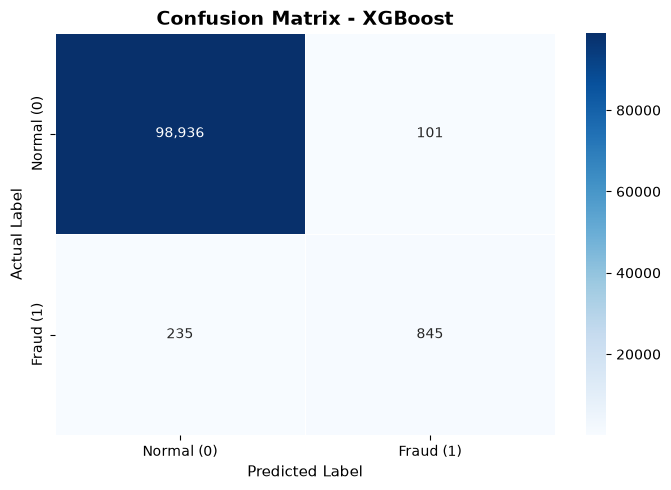

In [11]:
# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Normal (0)", "Fraud (1)"],
    yticklabels=["Normal (0)", "Fraud (1)"],
    linewidths=0.5,
    linecolor="white"
)

plt.title("Confusion Matrix - XGBoost", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    "../results/figures/xgboost_deployment_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Tạo lại toàn bộ X_test bằng hàm tiền xử lý mới
X_test_deployment = pd.concat(
    [
        preprocess_transaction(row.to_dict())
        for _, row in test_df[input_columns].iterrows()
    ],
    ignore_index=True
)

# So sánh với dữ liệu Test gốc
original_values = X_test_original.to_numpy(dtype=float)
deployment_values = X_test_deployment.to_numpy(dtype=float)

print("X_test gốc:", X_test_original.shape)
print("X_test triển khai:", X_test_deployment.shape)

print("\nHai bộ dữ liệu có giống hoàn toàn không?")
print(np.allclose(
    original_values,
    deployment_values,
    rtol=1e-6,
    atol=1e-8
))

print("\nSai lệch tuyệt đối lớn nhất:")
print(np.max(np.abs(original_values - deployment_values)))

X_test gốc: (100117, 79)
X_test triển khai: (100117, 79)

Hai bộ dữ liệu có giống hoàn toàn không?
True

Sai lệch tuyệt đối lớn nhất:
0.0


In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Nhãn thực tế
y_test_deployment = test_df["fraud"].astype(int)

# Dự đoán xác suất
y_test_proba = xgb_model.predict_proba(
    X_test_deployment
)[:, 1]

# Áp dụng threshold đã chọn trên Validation
y_test_pred = (
    y_test_proba >= threshold
).astype(int)

# Đánh giá mô hình
print("PRECISION:", precision_score(
    y_test_deployment, y_test_pred
))

print("RECALL:", recall_score(
    y_test_deployment, y_test_pred
))

print("F1-SCORE:", f1_score(
    y_test_deployment, y_test_pred
))

print("PR-AUC:", average_precision_score(
    y_test_deployment, y_test_proba
))

PRECISION: 0.8932346723044398
RECALL: 0.7824074074074074
F1-SCORE: 0.8341559723593287
PR-AUC: 0.9212934470684305


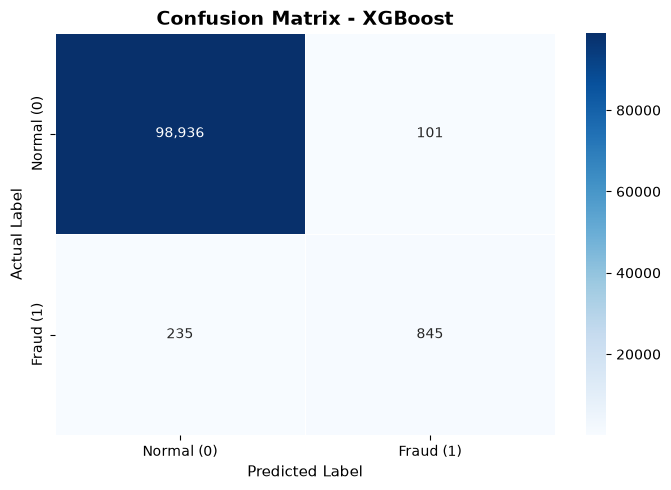

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Tính Confusion Matrix
cm = confusion_matrix(
    y_test_deployment,
    y_test_pred
)

# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Normal (0)", "Fraud (1)"],
    yticklabels=["Normal (0)", "Fraud (1)"],
    linewidths=0.5,
    linecolor="white"
)

plt.title("Confusion Matrix - XGBoost", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    "../results/figures/xgboost_deployment_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()